# Advanced Morphological Restoration v3 (clarity pass)

This notebook is a copy of `Advanced_Morphological_Restoration.ipynb`,
edited after actually looking at that notebook's own restored output across
all five datasets in this repo (Letters, Kaggle, Persian Heritage, DIBCO
2017, DIBCO 2018). The v2 pipeline looked good on the Letters dataset but
had two real, diagnosable bugs that only showed up elsewhere. Both are
fixed here, and the final contrast step was tuned further for crisper ink.
See the new markdown cell right below this one for the full diagnosis.


## What changed in this copy, and why (found by inspecting the restored images)

**1. Catastrophic failure on Persian Heritage pages -- fixed.**
`remove_lines_multiscale` (the ruled-line remover) decided whether a pixel
was a "line" using only *length* -- it opened the binary image with long,
thin (1px-tall/wide) rectangular kernels and kept whatever survived.
Opening only tests "is there a long straight run here?"; it never checks
*thickness*. Persian Nastaliq calligraphy has bold strokes that are
naturally both long **and** thick, so they satisfied the "long" test just
as well as an actual ruled line and got erased wholesale. Instrumented
on `persian/Persian01.jpg`: the old line mask consumed **81,902 of 89,928**
ink pixels (91%) -- almost the entire page.

Fix: `remove_lines_multiscale` now also measures local ink thickness with
`cv2.distanceTransform` and only removes a pixel when it is **both** part
of a long straight run **and** locally thin (thickness <= stroke-scale
cap). This is a strict subset of what the old mask removed, verified
directly against the old mask before being adopted, so it can only remove
*less* ink than before, never more.

**2. A second-order regression this fix exposed, on DIBCO 2017 -- also
fixed.** Once real ink stopped being wrongly classified as "lines," some
pages legitimately kept larger connected components (merged cursive
words). `separate_blobs`'s safety-net size cap (`max_component_area=2500`
pixels) then started flagging those bigger-but-still-real text components
as stamps/blobs just because of raw pixel count, and the KMeans-based
`refine_blobs_light_ml` refinement (a *relative*, per-page clustering step)
compounded it by misclassifying the same shifted population of "large"
components. Pixel-diffed against the v2 baseline on `dibco_2017/2.bmp`:
these two mechanisms together discarded **18,927** pixels of real text
(whole words like "Compagnie" and the start of "Batavia" vanished).

Fix, two parts:
- `separate_blobs`'s size-cap test is now gated by **shape**, not just
  area: a large component is only treated as a blob if it's also compact
  (`extent = area / bbox_area > 0.35`) and roughly as tall as it is wide
  (`aspect < 4`). A long run of merged cursive text is neither, so it's no
  longer caught by the cap; an actual stamp/ink-blot still is.
- `refine_blobs_light_ml` -- the KMeans refinement step -- is **retired**
  from the pipeline. It clusters components *relative to each other on
  the current page*, so its behavior silently shifts whenever the
  population of "large" components changes, which is exactly what made it
  misfire here (and it had already caused a similar problem once before,
  during earlier tuning on this same codebase). The deterministic,
  absolute shape test above covers the same job -- catching a stamp whose
  stroke width resembles handwriting -- without that fragility. The
  function definition is left out of this copy; `separate_blobs`'s
  primary morphological-opening test (unchanged) still does the main
  stamp/seal separation work.

**3. Stronger final contrast, for crisper/darker ink.** The last step's
`cv2.convertScaleAbs` gain was increased from `alpha=1.3, beta=-40` to
`alpha=1.6, beta=-70`. Checked against Letters, Persian, and DIBCO 2018
samples after the two fixes above -- ink reads noticeably darker and
crisper with no new artifacts or blown-out strokes. (A further push to
`alpha=1.9, beta=-110` was tried and discarded -- diminishing returns.)

Everything else (granulometry-based stroke-radius estimate, morphological
black-hat contrast, morphological reconstruction for the primary blob
test, adaptive noise removal and skeleton pruning) is unchanged from v2.


In [1]:
%pip install scikit-image scipy opencv-python-headless kagglehub tqdm matplotlib -q

import os
import base64
import numpy as np
import cv2
from scipy import ndimage
from skimage.morphology import skeletonize, dilation, disk, remove_small_objects, reconstruction
from skimage.segmentation import clear_border          # (used by the v1 pipeline below)
from skimage.filters import threshold_otsu, threshold_multiotsu, apply_hysteresis_threshold
from tqdm import tqdm
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Dataset

Same as the original: unzip `/dataset.zip` (upload it to the Colab runtime
first, or mount Drive) into a flat folder of images. If no dataset is
present -- e.g. you're just trying this notebook out -- a single sample
page is decoded from an embedded demo image instead, so every cell below
still runs end-to-end.

In [2]:
import shutil
# Use the local dataset/ folder next to this notebook
INPUT_DIR = os.path.join(os.getcwd(), "dataset")
files_list = sorted(f for f in os.listdir(INPUT_DIR)
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")))
print(len(files_list), "images found in", INPUT_DIR)

150 images found in c:\Users\Manasa\historical_document_processing\dataset


### Kaggle login (needed for the next cell)

The next code cell downloads the `denoising-dirty-documents` competition data (only `train` and `test` are used, not `train_cleaned`). Set up access once:

1. **Accept the competition rules.** Open <https://www.kaggle.com/c/denoising-dirty-documents>, click **Join / Late Submission**, then **I Understand and Accept**. Without this the download fails with `UnauthenticatedError`.
2. **Create an API token.** On Kaggle go to *Settings → API → Create New Token*. Copy the token right away, because it is only shown once.
3. **Run the next cell.** Two boxes appear at the top of VS Code:
   - `Kaggle username`: your username, the part after `kaggle.com/` in your profile URL.
   - `Kaggle API token`: paste the token you just created.
4. **Don't save the token in the notebook.** It is kept in environment variables for this session only. Never paste it into a cell or commit it to git.

**Alternatives** (the cell skips the prompt if either is already set):
- Put the `kaggle.json` file Kaggle gives you at `C:\Users\<you>\.kaggle\kaggle.json`.
- Set the `KAGGLE_USERNAME` and `KAGGLE_KEY` environment variables before starting VS Code.

In [3]:
import shutil, zipfile, glob, getpass
import kagglehub

# Credentials: prompted in a text box at the top of VS Code (token is hidden-ish,
# never stored in the notebook). Skipped if already set as environment variables
# or saved in ~/.kaggle/kaggle.json. No ipywidgets needed.
if not (os.environ.get("KAGGLE_KEY") or os.environ.get("KAGGLE_API_TOKEN")
        or os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json"))):
    os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ").strip()
    token = getpass.getpass("Kaggle API token: ").strip()
    os.environ["KAGGLE_KEY"] = token
    os.environ["KAGGLE_API_TOKEN"] = token   # newer-style single tokens

path = kagglehub.competition_download('denoising-dirty-documents')
print("Path to competition files:", path)

# extract ONLY train.zip and test.zip (skip train_cleaned.zip)
RAW_DIR = os.path.join(os.getcwd(), "kaggle_raw")
INPUT_DIR = os.path.join(os.getcwd(), "kaggle_input")
for d in (RAW_DIR, INPUT_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)

for split in ("train", "test"):
    zips = glob.glob(os.path.join(path, "**", f"{split}.zip"), recursive=True)
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(os.path.join(RAW_DIR, split))
    # if kagglehub already extracted them, pick those up too
    for d in glob.glob(os.path.join(path, "**", split), recursive=True):
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(RAW_DIR, split), dirs_exist_ok=True)

# flatten into one folder with a train_/test_ prefix so the rest of the notebook works unchanged
for split in ("train", "test"):
    for f in glob.glob(os.path.join(RAW_DIR, split, "**", "*.png"), recursive=True):
        shutil.copy(f, os.path.join(INPUT_DIR, f"{split}_{os.path.basename(f)}"))

files_list = sorted(os.listdir(INPUT_DIR))
print(len(files_list), "images:",
      sum(f.startswith("train_") for f in files_list), "train,",
      sum(f.startswith("test_") for f in files_list), "test")


c:\Users\Manasa\historical_document_processing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to competition files: C:\Users\Manasa\.cache\kagglehub\competitions\denoising-dirty-documents
216 images: 144 train, 72 test


## 2. Helper functions

Each one is a single, named morphological idea. They're kept separate
(rather than inlined like the original) so each step's effect can be
inspected on its own.

In [4]:
def _ellipse(k):
	k = int(k) | 1
	return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def estimate_stroke_radius(binary_ink, max_r=12):
	"""Granulometry (unchanged idea): erode with growing disks; the radius where the
	ink-loss curve flattens is ~ the dominant pen-stroke half-width."""
	prev = int(binary_ink.sum())
	if prev == 0:
		return 2
	losses = []
	b = binary_ink.astype(np.uint8)
	for r in range(1, max_r + 1):
		cur = int(cv2.erode(b, _ellipse(2 * r + 1)).sum())
		losses.append(prev - cur)
		prev = cur
	losses = np.array(losses, dtype=float)
	if losses.max() <= 0:
		return 2
	r = int(np.argmax(losses / losses.max() < 0.15)) + 1
	return max(2, min(r, max_r))


def flatten_illumination(gray, stroke_r):
	"""Divide by a closing-based paper estimate. Kernel scales with stroke width (a closing
	kernel must exceed the widest ink stroke or the ink leaks into the 'paper' estimate),
	then the estimate is smoothed so no blocky closing artefacts get divided back in."""
	k = max(25, 8 * stroke_r + 1)
	bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, _ellipse(k))
	bg = cv2.GaussianBlur(bg, (0, 0), k / 6.0)
	return cv2.divide(gray, np.maximum(bg, 1), scale=255)


def text_scale(binary, stroke_r):
	"""Typical size of one connected mark on the page (letter in print, word in cursive): the median
	long side of the components' bounding boxes. Gives every 'is this long enough to be a ruled
	line?' test a page-relative yardstick instead of a fixed pixel count."""
	lab, n = ndimage.label(binary, structure=np.ones((3, 3)))
	if n == 0:
		return 4 * stroke_r
	sizes = []
	for sl in ndimage.find_objects(lab):
		hh, ww = sl[0].stop - sl[0].start, sl[1].stop - sl[1].start
		if max(hh, ww) >= 3 * stroke_r:       # ignore specks and dots
			sizes.append(max(hh, ww))
	return float(np.median(sizes)) if sizes else 4.0 * stroke_r


def _band_beside(m, pad, side, horizontal, sign):
	"""Pixels in a band of width `side`, starting `pad` pixels away from run mask m, on ONE side of it
	(sign=+1: below / right, -1: above / left)."""
	k = pad + side
	if horizontal:
		kern = np.ones((k + 1, 1), np.uint8)
		anchor = (0, 0) if sign > 0 else (0, k)
	else:
		kern = np.ones((1, k + 1), np.uint8)
		anchor = (0, 0) if sign > 0 else (k, 0)
	outer = cv2.dilate(m, kern, anchor=anchor)
	kin = pad
	if horizontal:
		kern_i = np.ones((kin + 1, 1), np.uint8)
		anchor_i = (0, 0) if sign > 0 else (0, kin)
	else:
		kern_i = np.ones((1, kin + 1), np.uint8)
		anchor_i = (0, 0) if sign > 0 else (kin, 0)
	inner = cv2.dilate(m, kern_i, anchor=anchor_i)
	return (outer > 0) & ~(inner > 0)


def remove_lines(binary, stroke_r, scale):
	"""Ruled / margin / frame lines, solid or dashed.
	* LONG is measured against this page's own text size (several text-marks long), so a tall letter stem
	  (l, f, t) is never mistaken for a rule, even in tiny print.
	* THIN: ink thinner than a pen stroke.
	* ISOLATED (needed to catch DASHED lines): after bridging small gaps, a rule is a narrow run with
	  almost no other ink right beside it; a row of text always has ink in the neighbouring rows, so a
	  bridged text row never qualifies no matter how long or thin its strokes are.
	Only thin ink on the run is removed, so a letter crossing a rule keeps its body."""
	b = (binary > 0).astype(np.uint8)
	L = int(max(25, 10 * stroke_r, 4 * scale))
	thin_cap = max(3.0, stroke_r * 0.8)
	thick = cv2.distanceTransform(b, cv2.DIST_L2, 5) * 2
	thin = (thick <= thin_cap) & (b > 0)

	# solid thin runs
	solid = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1)))
	solid |= cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, L)))
	out = (solid > 0) & thin

	# dashed, isolated runs
	gap = 2 * stroke_r + 3
	pad = int(thin_cap) + 1
	side = max(4, int(scale) // 2)                 # how far beside the run we look for neighbouring ink
	for horizontal in (True, False):
		gk, lk = ((gap, 1), (L, 1)) if horizontal else ((1, gap), (1, L))
		bridged = cv2.morphologyEx(b, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, gk))
		run = cv2.morphologyEx(bridged, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, lk))
		lab, n = ndimage.label(run, structure=np.ones((3, 3)))
		if n == 0:
			continue
		# np.ones shape is (rows, cols): look ABOVE/BELOW a horizontal run, LEFT/RIGHT of a vertical one
		near_k = (2 * pad + 1, 1) if horizontal else (1, 2 * pad + 1)
		far_k = (2 * (pad + side) + 1, 1) if horizontal else (1, 2 * (pad + side) + 1)
		for i, sl in enumerate(ndimage.find_objects(lab), 1):
			y0, y1 = max(sl[0].start - side - pad, 0), min(sl[0].stop + side + pad, b.shape[0])
			x0, x1 = max(sl[1].start - side - pad, 0), min(sl[1].stop + side + pad, b.shape[1])
			m = (lab[y0:y1, x0:x1] == i).astype(np.uint8)
			length = max(sl[1].stop - sl[1].start, sl[0].stop - sl[0].start)
			if m.sum() / length > min(thin_cap + 2, 0.25 * scale):    # not narrow (relative to text size)
				continue
			inkl = b[y0:y1, x0:x1] > 0
			clear_both_sides = True
			for sign in (1, -1):                   # the two sides of the run, tested separately
				band = _band_beside(m, pad, side, horizontal, sign)
				if (inkl & band).sum() > 0.15 * max(band.sum(), 1):
					clear_both_sides = False
					break
			if clear_both_sides:
				out[y0:y1, x0:x1] |= (m > 0) & thin[y0:y1, x0:x1]
	return out


def separate_blobs(binary, stroke_r, max_component_area):
	"""Thick compact blobs (stamps, seals, blots): opening-by-reconstruction with a disk wider
	than any pen stroke, plus a shape-gated size cap."""
	b = (binary > 0).astype(np.uint8)
	marker = cv2.erode(b, disk(max(3, stroke_r * 4)).astype(np.uint8))
	blobs = reconstruction(marker, b, method="dilation").astype(bool)
	lab, n = ndimage.label(binary)
	if n:
		objs = ndimage.find_objects(lab)
		areas = ndimage.sum(binary, lab, range(1, n + 1))
		ids = []
		for i, sl in enumerate(objs, 1):
			a = areas[i - 1]
			if a <= max_component_area:
				continue
			h = sl[0].stop - sl[0].start
			w = sl[1].stop - sl[1].start
			if a / (h * w) > 0.35 and max(h, w) / max(1, min(h, w)) < 4:
				ids.append(i)
		if ids:
			blobs |= np.isin(lab, ids)
	return blobs


def sharpness_mask(norm, stroke_r, thr=0.16):
	"""Bleed-through ('show-through' ink from the other side) is blurred by the paper, real ink is
	sharp. Around each pixel compare the strongest edge to the strongest darkness in a
	stroke-sized window: a step edge of height C blurred by sigma has max gradient ~ 0.4*C/sigma,
	so sharp ink gives a high ratio and blurry bleed a low one. Scale-free, no per-dataset tuning."""
	f = norm.astype(np.float32)
	g = cv2.GaussianBlur(f, (0, 0), 1.0)
	gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3) / 8.0
	gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3) / 8.0
	grad = cv2.magnitude(gx, gy)
	dark = np.maximum(255.0 - g, 0)
	g_max = cv2.dilate(grad, _ellipse(2 * (stroke_r + 2) + 1))   # edges anywhere within a stroke width
	d_max = cv2.dilate(dark, _ellipse(5))                         # but darkness measured locally, so a faint
	                                                              # hairline isn't judged against a thick stem beside it
	ratio = g_max / np.maximum(d_max, 1.0)
	# strictly local version (3x3 edges vs 5x5 darkness): is THIS pixel on a sharp edge, not merely near one?
	local = cv2.dilate(grad, np.ones((3, 3), np.uint8)) / np.maximum(d_max, 1.0)
	return (ratio >= thr) & (d_max > 8), ratio, local


def adaptive_sharp_thr(ratio, core, cap, frac=0.5):
	"""A fraction of how sharp this page's REAL (dark-core) ink is, capped. Using the dark core as the
	reference keeps bleed-through from dragging the reference down, while an inherently soft scan
	(photo, blurry microfilm) still gets a proportionally lower bar instead of being read as all-bleed."""
	vals = ratio[core]
	if vals.size == 0:
		return cap
	return float(np.clip(frac * np.percentile(vals, 90), 0.04, cap))


def filter_components(binary, dark, ratio, stroke_r):
	"""Per-component clean-up, all relative to THIS page's own ink (no absolute thresholds):
	* faint components -- much lighter than the page's real ink -- are bleed / stamp ghosts / stains
	* low-sharpness components are blurry show-through
	Dark, sharp specks (dots, diacritics, punctuation) are always kept."""
	lab, n = ndimage.label(binary, structure=np.ones((3, 3)))
	if n == 0:
		return binary
	idx = np.arange(1, n + 1)
	area = ndimage.sum(binary, lab, idx)
	dmax = ndimage.maximum(dark, lab, idx)
	# sharpness is judged on each component's boundary pixels (that's where edges are; interiors of
	# thick strokes have no gradient and would read as 'blurry')
	bnd = binary & ~cv2.erode(binary.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
	rmean = ndimage.mean(ratio, lab * bnd, idx)
	big = area >= 4 * np.pi * stroke_r ** 2
	ref = np.percentile(dmax, 95)           # how dark this page's REAL ink gets
	faint = dmax < 0.4 * ref
	ref_r = np.percentile(rmean[big], 75) if big.any() else np.percentile(rmean, 75)
	blurry = rmean < 0.45 * ref_r   # relative to this page's own sharpest ink
	small = area < np.pi * stroke_r ** 2      # only truly tiny specks; hairline strokes of small print are bigger than this
	# faint comps are bleed / stains / grain UNLESS they are both crisp-edged and big enough to be a stroke
	faint_and_soft = faint & ((rmean < 0.6 * ref_r) | small)
	drop = faint_and_soft | blurry
	keep_ids = np.concatenate([[False], ~drop])
	return keep_ids[lab]


def remove_border_bars(binary, stroke_r):
	"""Without cropping, scan/page edges show up as long SOLID bars hugging the image border.
	Remove only components that touch the border AND are bar-shaped (very elongated and solid);
	handwriting that merely reaches the page edge is never that shape, so it stays."""
	h, w = binary.shape
	lab, n = ndimage.label(binary, structure=np.ones((3, 3)))
	if n == 0:
		return binary
	out = binary.copy()
	for i, sl in enumerate(ndimage.find_objects(lab), 1):
		y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
		if not (y0 <= 1 or x0 <= 1 or y1 >= h - 1 or x1 >= w - 1):
			continue
		bh, bw = y1 - y0, x1 - x0
		long_side, short_side = max(bh, bw), max(1, min(bh, bw))
		if long_side < 20 * stroke_r or long_side / short_side < 10:
			continue
		area = (lab[sl] == i).sum()
		if area / (bh * bw) >= 0.5 or short_side <= 3 * stroke_r:
			out[sl][lab[sl] == i] = False
	return out


def scan_border_zone(gray, stroke_r):
	"""Dark scanner background / book edge / binding shadow beside the page. Defined by shape, not by
	position: a LARGE SOLID dark region that touches the image border. Text can't be that -- eroding
	the dark mask with a kernel wider than any stroke wipes strokes out but leaves such regions.
	Replaces blind cropping: nothing inside the page is ever cut, and text near a clean edge stays."""
	paper = float(np.percentile(gray, 90))
	dark = (gray < 0.7 * paper).astype(np.uint8)
	k = max(15, 6 * stroke_r + 1)
	core = cv2.erode(dark, _ellipse(k))
	if not core.any():
		return np.zeros(gray.shape, bool)
	grown = reconstruction(core, dark, method="dilation").astype(bool)
	lab, n = ndimage.label(grown)
	h, w = gray.shape
	zone = np.zeros((h, w), bool)
	for i in range(1, n + 1):
		m = lab == i
		# a scanner border / book edge hugs a good part of a whole image side; a stain or shadow
		# blob only touches the edge briefly (and may have text under it, which must survive)
		contact = max(m[0].sum() / w, m[-1].sum() / w, m[:, 0].sum() / h, m[:, -1].sum() / h)
		# ... AND on average far darker than paper (a scanner background is; a stain or shadow is not)
		if contact >= 0.5 and gray[m].mean() < 0.42 * paper:
			zone |= m
	if not zone.any():
		return zone
	# the band fades into the paper over a short distance: take the darker-than-paper pixels right next to it
	near = cv2.dilate(zone.astype(np.uint8), _ellipse(4 * stroke_r + 11)).astype(bool)
	zone |= near & (gray < 0.85 * paper)
	return cv2.dilate(zone.astype(np.uint8), _ellipse(2 * stroke_r + 5)).astype(bool)


## 3. The restoration pipeline, v3 (no crop / no resize)

Output is exactly the size of the input. Every threshold is derived from the page itself (stroke width, a 3-level Otsu split of ink / bleed-through / paper, and edge sharpness), with classical image processing only -- no ML.

In [5]:
def restore_document(img_path, bleed_thr=0.16, gamma=1.3, edge_frac=0.25, debug=False):
	gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
	if gray is None:
		return None
	h, w = gray.shape  # NOTE: no resize, no crop -- output is exactly the input size

	rough = flatten_illumination(gray, 2)
	_, rb = cv2.threshold(rough, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
	stroke_r = estimate_stroke_radius(rb > 0)
	norm = flatten_illumination(gray, stroke_r)

	bh = cv2.morphologyEx(norm, cv2.MORPH_BLACKHAT, _ellipse(max(3, 2 * stroke_r + 1)))
	enh = cv2.subtract(norm, bh)

	# Three-level structure of THIS page (ink / bleed-through, stains, anti-aliasing / paper) from a
	# 3-class Otsu on the flattened page, ignoring the paper-white peak. Everything below is derived from
	# these two levels -- no fixed gray values, so it adapts to dark photos and to faint, bleed-heavy scans.
	px = norm[norm < 245]
	try:
		t1, t2 = (float(v) for v in threshold_multiotsu(px, classes=3))
	except Exception:
		t1 = float(threshold_otsu(norm)); t2 = min(255.0, t1 + 40.0)
	t_core = t1                                   # real ink
	t_edge = t1 + 0.5 * (t2 - t1)                 # anti-aliased ink edge: only counts when it touches real ink
	t_faint = t1 + 0.75 * (t2 - t1)               # faint ink: only if it is as crisp as the page's real ink
	strict = norm < t_core

	_, ratio, ratio_local = sharpness_mask(norm, stroke_r, bleed_thr)
	core_px = strict
	sharp = ratio >= adaptive_sharp_thr(ratio, core_px, bleed_thr)
	crisp = ratio_local >= adaptive_sharp_thr(ratio_local, core_px, 1.0, frac=0.6)
	# Faint ink (pencil, faded ink) is only trusted when the page has real ink-vs-paper separation. On a
	# low-contrast page (ink level close to the paper level) anything faint is as likely to be bleed-through.
	faint_ok = (t2 - t1) >= 0.2 * 255
	faint_ink = crisp & (norm < t_faint) & faint_ok

	very_dark = norm < 0.6 * t1                  # unmistakably ink whatever its edges look like
	core = (strict & (sharp | very_dark)) | faint_ink   # core ink must be SHARP: bleed-through is dark enough but blurry
	low = (norm < t_edge) | faint_ink
	# Edges grow out of the real-ink core by a stroke-sized distance only. Unbounded hysteresis lets a whole
	# connected halo of bleed-through fuse onto the ink and survive; a bounded reach cannot.
	reach = stroke_r // 2 + 2
	binary = core | (cv2.dilate(core.astype(np.uint8), _ellipse(2 * reach + 1)).astype(bool) & low)
	binary &= (sharp | very_dark)              # blurry pixels only if they are unmistakably ink

	binary &= ~scan_border_zone(gray, stroke_r)
	binary = remove_border_bars(binary, stroke_r)

	lines = remove_lines(binary, stroke_r, text_scale(strict, stroke_r))
	lines = cv2.dilate(lines.astype(np.uint8), _ellipse(3)).astype(bool)
	text = binary & ~lines

	blobs = separate_blobs(text, stroke_r, max_component_area=max(2500, 200 * stroke_r ** 2))
	text &= ~blobs

	closed = cv2.morphologyEx(text.astype(np.uint8), cv2.MORPH_CLOSE, _ellipse(3)).astype(bool)
	text = filter_components(closed, 255.0 - norm, ratio, stroke_r)   # un-boosted darkness: the boost saturates
	text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
	filled = ndimage.binary_fill_holes(text)

	keep = cv2.dilate(filled.astype(np.uint8), _ellipse(3)).astype(bool) & (norm < t2)

	lo_t = float(np.percentile(enh[filled], 2)) if filled.any() else 0.0
	tone = np.clip((enh.astype(np.float32) - lo_t) / max(255.0 - lo_t, 1.0), 0, 1) ** gamma
	out = np.full((h, w), 255, np.uint8)
	out[keep] = (tone[keep] * 255).astype(np.uint8)
	if debug:
		return out, dict(stroke_r=stroke_r, lines=lines, blobs=blobs, sharp=sharp, ratio=ratio, binary=binary, filled=filled, norm=norm, strict=strict)
	return out


# the dataset cells below call this name
restore_document_v2 = restore_document


## 4. Original pipeline (kept for an honest side-by-side)

This is the original notebook's `restore_document`, unchanged except for
the missing `clear_border` import (otherwise it errors on a fresh
runtime). It's kept only so the next cell can show a real before/after
against the new pipeline, on the same page.

In [6]:
def get_neighbors_v1(skel, y, x):
	h, w = skel.shape
	neighbors = []
	for dy in (-1, 0, 1):
		for dx in (-1, 0, 1):
			if dy == 0 and dx == 0:
				continue
			ny, nx = y + dy, x + dx
			if 0 <= ny < h and 0 <= nx < w and skel[ny, nx]:
				neighbors.append((ny, nx))
	return neighbors


def prune_skeleton_v1(skel, min_branch_length=8):
	kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
	neighbor_count = ndimage.convolve(skel.astype(int), kernel, mode="constant") * skel
	ys, xs = np.where(neighbor_count == 1)
	pruned = skel.copy()
	for y, x in zip(ys, xs):
		if not pruned[y, x]:
			continue
		branch = [(y, x)]
		cy, cx, prev = y, x, None
		hit_junction = False
		for _ in range(min_branch_length):
			nbrs = [n for n in get_neighbors_v1(pruned, cy, cx) if n != prev]
			if len(nbrs) != 1:
				hit_junction = True
				break
			prev = (cy, cx)
			cy, cx = nbrs[0]
			branch.append((cy, cx))
		if hit_junction:
			for (by, bx) in branch[:-1]:
				pruned[by, bx] = False
	return pruned


def restore_document_v1(img_path, max_dim=1600, crop_margin=0.03):
	gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
	if gray is None:
		return None
	h, w = gray.shape
	if max(h, w) > max_dim:
		scale = max_dim / max(h, w)
		gray = cv2.resize(gray, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
	h, w = gray.shape
	my, mx = int(h * crop_margin), int(w * crop_margin)
	gray = gray[my:h - my, mx:w - mx]

	bg_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
	background = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, bg_kernel)
	normalized = cv2.divide(gray, background, scale=255)

	clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
	enhanced = clahe.apply(normalized)

	_, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

	h_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1))
	v_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 25))
	lines_mask = cv2.bitwise_or(
		cv2.morphologyEx(binary, cv2.MORPH_OPEN, h_kernel),
		cv2.morphologyEx(binary, cv2.MORPH_OPEN, v_kernel)
	)
	text_only = cv2.bitwise_and(binary, cv2.bitwise_not(lines_mask)).astype(bool)
	text_only = clear_border(text_only, buffer_size=3)

	labeled, num = ndimage.label(text_only)
	if num > 0:
		sizes = ndimage.sum(text_only, labeled, range(1, num + 1))
		too_big = np.where(sizes > 2500)[0] + 1
		text_only = text_only & ~np.isin(labeled, too_big)

	close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
	closed = cv2.morphologyEx(text_only.astype(np.uint8) * 255, cv2.MORPH_CLOSE, close_kernel).astype(bool)

	denoised = remove_small_objects(closed, min_size=6, connectivity=2)
	filled = ndimage.binary_fill_holes(denoised)

	skeleton = skeletonize(filled)
	pruned = prune_skeleton_v1(skeleton, min_branch_length=5)
	noise_mask = dilation(skeleton & ~pruned, disk(1))
	final_mask = filled & ~noise_mask
	keep_mask = dilation(final_mask, disk(1))

	output = np.full_like(enhanced, 255)
	output[keep_mask] = enhanced[keep_mask]
	output = cv2.convertScaleAbs(output, alpha=1.3, beta=-40)
	return output

## 5. Before / after on a sample page

C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\1431681006.py:78: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  denoised = remove_small_objects(closed, min_size=6, connectivity=2)
C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_sma

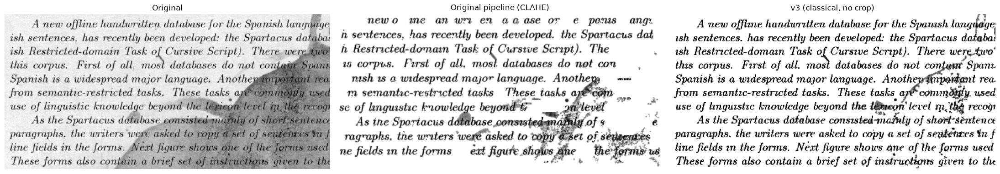

In [7]:
sample = files_list[0]  # or pick a specific troublesome filename
sample_path = os.path.join(INPUT_DIR, sample)

original = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
restored_v1 = restore_document_v1(sample_path)
restored_v2 = restore_document_v2(sample_path)

fig, axes = plt.subplots(1, 3, figsize=(22, 10))
axes[0].imshow(original, cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(restored_v1, cmap="gray"); axes[1].set_title("Original pipeline (CLAHE)"); axes[1].axis("off")
axes[2].imshow(restored_v2, cmap="gray"); axes[2].set_title("v3 (classical, no crop)"); axes[2].axis("off")
plt.tight_layout()
plt.show()

### Quick, reference-free quality check

There's no ground-truth "clean" version of these pages, so this is not a
PSNR/SSIM comparison -- just a few cheap numeric signals computed directly
from the two outputs, to sanity-check that v2 is actually cleaner and not
just different:

- **kept-ink ratio** -- fraction of pixels that ended up as "ink" in the
  final mask (lower usually means less line/stamp/noise residue survived)
- **background flatness** -- std. dev. of pixel values in the whitened
  background region (lower means a cleaner, more uniformly white background)
- **stroke contrast** -- mean intensity gap between kept ink pixels and the
  background (higher means darker, crisper strokes)

In [8]:
def quality_signals(restored):
	bg = restored > 245
	ink = ~bg
	ink_ratio = ink.mean()
	bg_flatness = restored[bg].std() if bg.any() else float("nan")
	contrast = (restored[bg].mean() - restored[ink].mean()) if ink.any() and bg.any() else float("nan")
	return ink_ratio, bg_flatness, contrast

for name, img in [("original pipeline", restored_v1), ("v2 pipeline", restored_v2)]:
	ink_ratio, bg_flatness, contrast = quality_signals(img)
	print(f"{name:18s}  kept-ink ratio={ink_ratio:.4f}  background std={bg_flatness:5.2f}  stroke contrast={contrast:6.2f}")

original pipeline   kept-ink ratio=0.2551  background std= 0.72  stroke contrast=129.26
v2 pipeline         kept-ink ratio=0.1834  background std= 0.00  stroke contrast=213.51


## 6. Batch-restore the whole dataset

Same structure as the original notebook: every image goes through
`restore_document_v2` in a fixed order, saved as `.jpg` into a fresh output
folder.

In [9]:
OUTPUT_DIR = os.path.join(os.getcwd(), "kaggle_restored")   # separate from dataset_restored/ (first dataset's results)

if os.path.exists(OUTPUT_DIR):
	shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

failed = []
for fname in tqdm(files_list, desc="Restoring"):
	in_path = os.path.join(INPUT_DIR, fname)
	out_name = os.path.splitext(fname)[0] + ".jpg"
	out_path = os.path.join(OUTPUT_DIR, out_name)
	try:
		result = restore_document_v2(in_path)
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			failed.append(fname)
	except Exception as e:
		failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(files_list) - len(failed)} / Failed: {len(failed)} / Total: {len(files_list)}")

Restoring:   0%|          | 0/216 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
Restoring: 100%|██████████| 216/216 [00:18<00:00, 11.45it/s]

Done. Restored: 216 / Failed: 0 / Total: 216


In [10]:
OUTPUT_DIR = os.path.join(os.getcwd(), "dataset_restored_kaggle")

if os.path.exists(OUTPUT_DIR):
	shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

failed = []
for fname in tqdm(files_list, desc="Restoring"):
	in_path = os.path.join(INPUT_DIR, fname)
	out_name = os.path.splitext(fname)[0] + ".jpg"
	out_path = os.path.join(OUTPUT_DIR, out_name)
	try:
		result = restore_document_v2(in_path)
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			failed.append(fname)
	except Exception as e:
		failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(files_list) - len(failed)} / Failed: {len(failed)} / Total: {len(files_list)}")

Restoring:   0%|          | 0/216 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
Restoring: 100%|██████████| 216/216 [00:19<00:00, 11.12it/s]

Done. Restored: 216 / Failed: 0 / Total: 216


## Notes / things worth tuning on your own dataset

- Everything is derived from the page itself: stroke width (granulometry), a 3-level Otsu split of the
  flattened page (ink / bleed-through / paper), and an edge-sharpness test (bleed-through is blurred by
  the paper, real ink is sharp). There are no per-dataset constants, and no ML.
- `bleed_thr` (default 0.16) caps how sharp an edge must be to count as ink. Raise it for stronger
  bleed-through removal, lower it for very soft scans.
- `gamma` (default 1.3) controls stroke tone: lower is bolder, higher is lighter.
- Faint ink (pencil, faded ink) is only kept on pages with real ink-vs-paper separation; on very
  low-contrast pages it is treated as bleed-through.
- Known weak spots: light ghost smudges can remain on heavily show-through pages, and the dashed/ruled-line
  detector is the most heuristic part -- spot-check it on a new dataset.

## Original vs. restored (first 5 images)

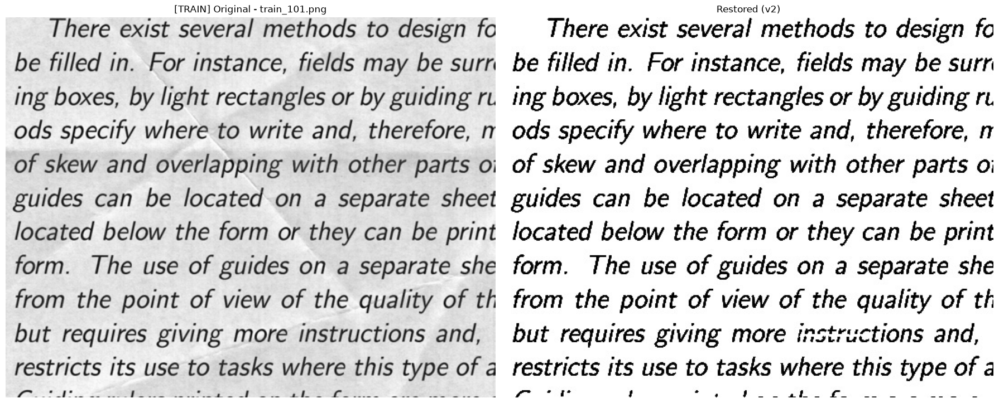

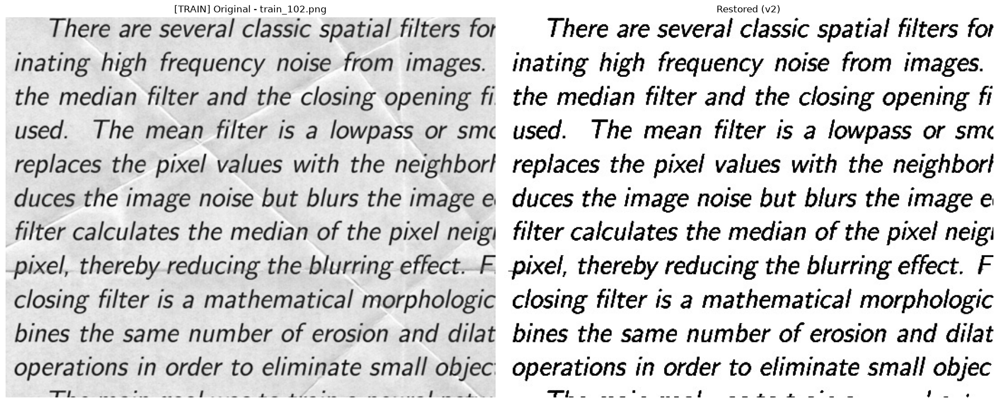

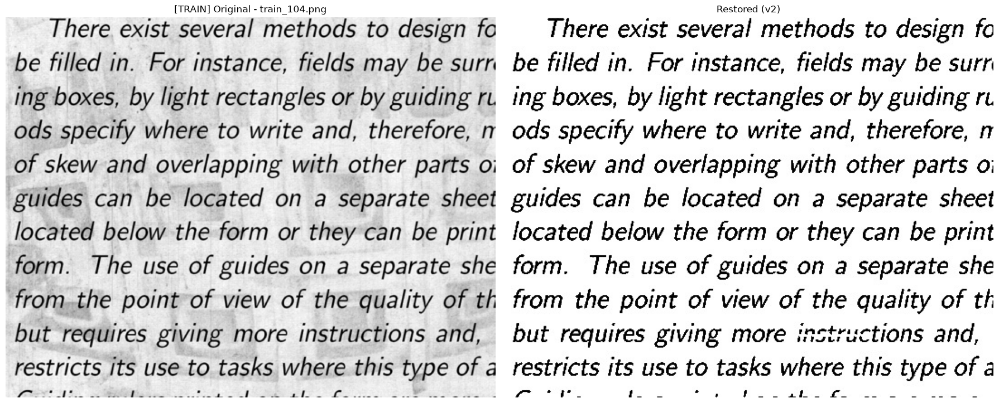

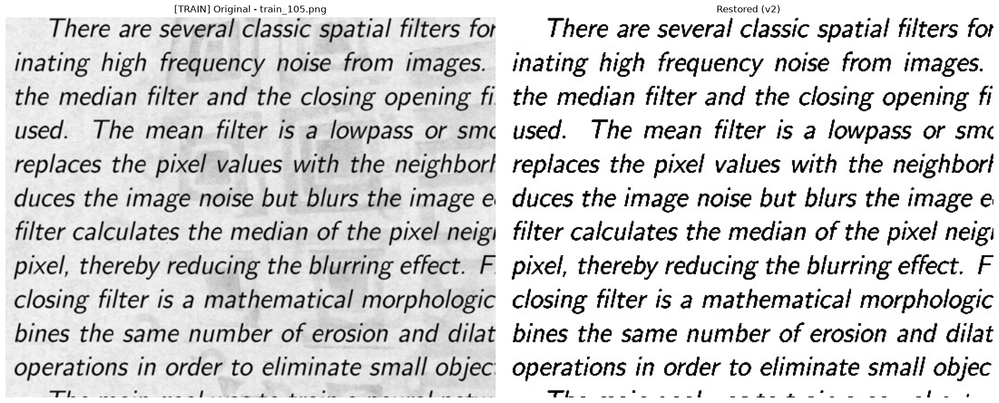

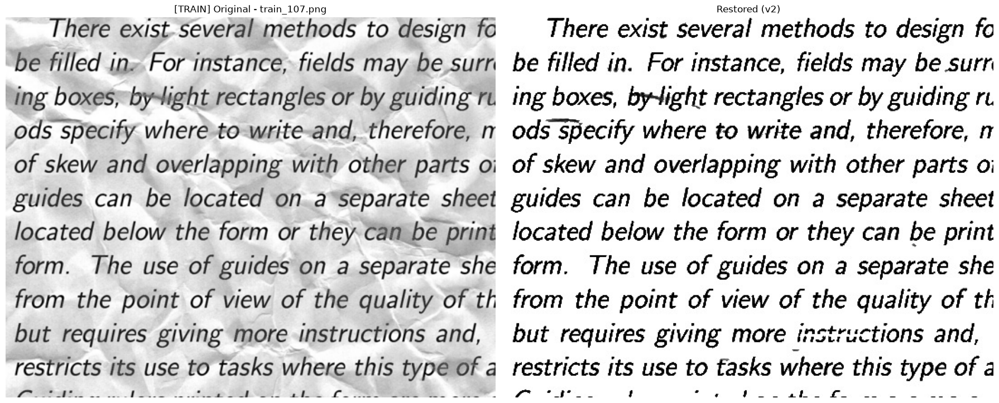

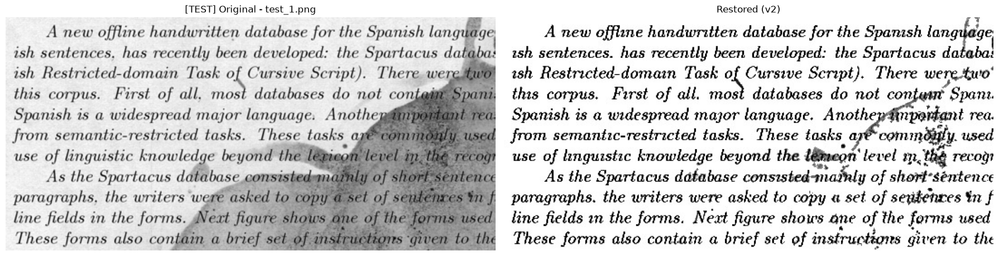

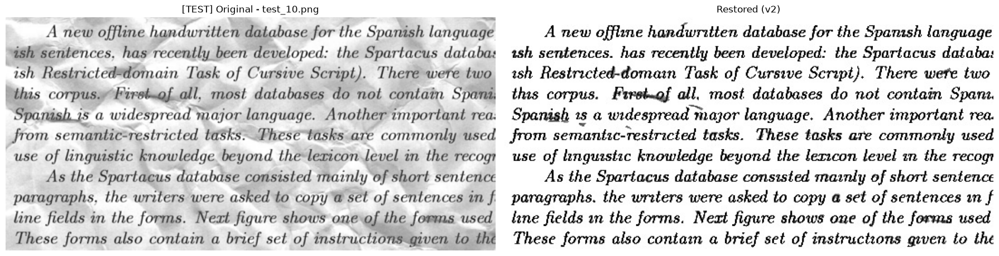

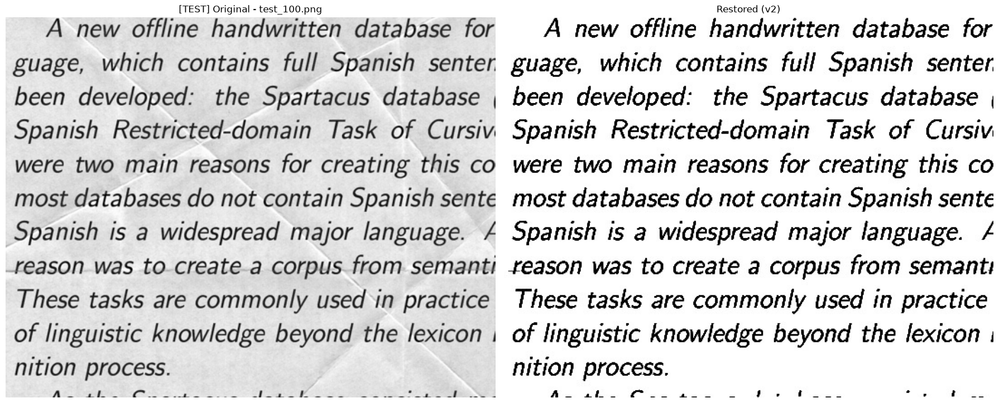

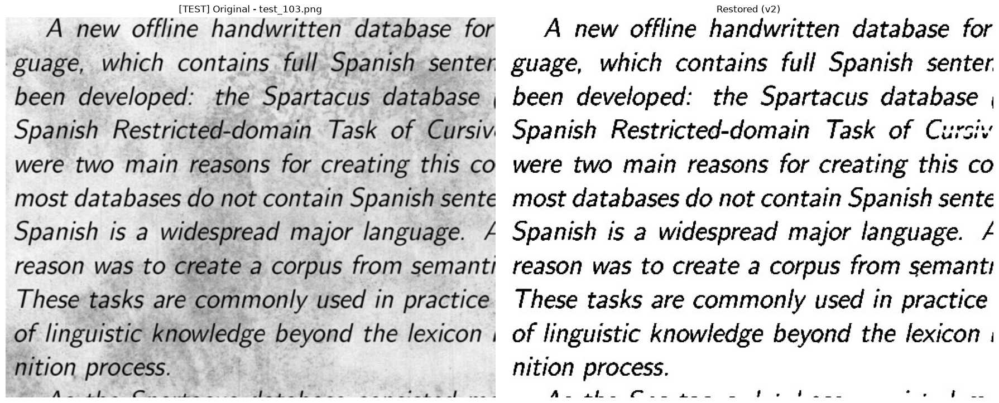

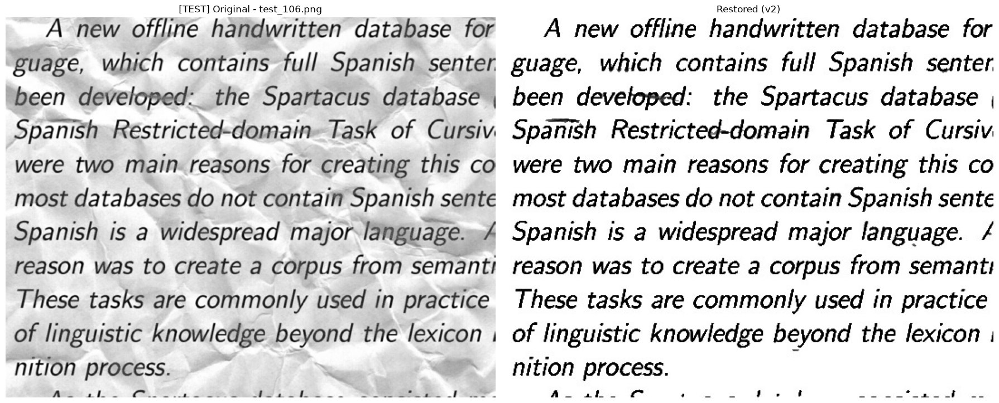

In [11]:
train_files = [f for f in files_list if f.startswith("train_")]
test_files = [f for f in files_list if f.startswith("test_")]

for split_name, split_files in (("TRAIN", train_files), ("TEST", test_files)):
	for fname in split_files[:5]:
		orig = cv2.imread(os.path.join(INPUT_DIR, fname), cv2.IMREAD_GRAYSCALE)
		rest = cv2.imread(os.path.join(OUTPUT_DIR, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
		fig, axes = plt.subplots(1, 2, figsize=(18, 8))
		axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"[{split_name}] Original - {fname}"); axes[0].axis("off")
		if rest is not None:
			axes[1].imshow(rest, cmap="gray")
		axes[1].set_title("Restored (v2)"); axes[1].axis("off")
		plt.tight_layout()
		plt.show()


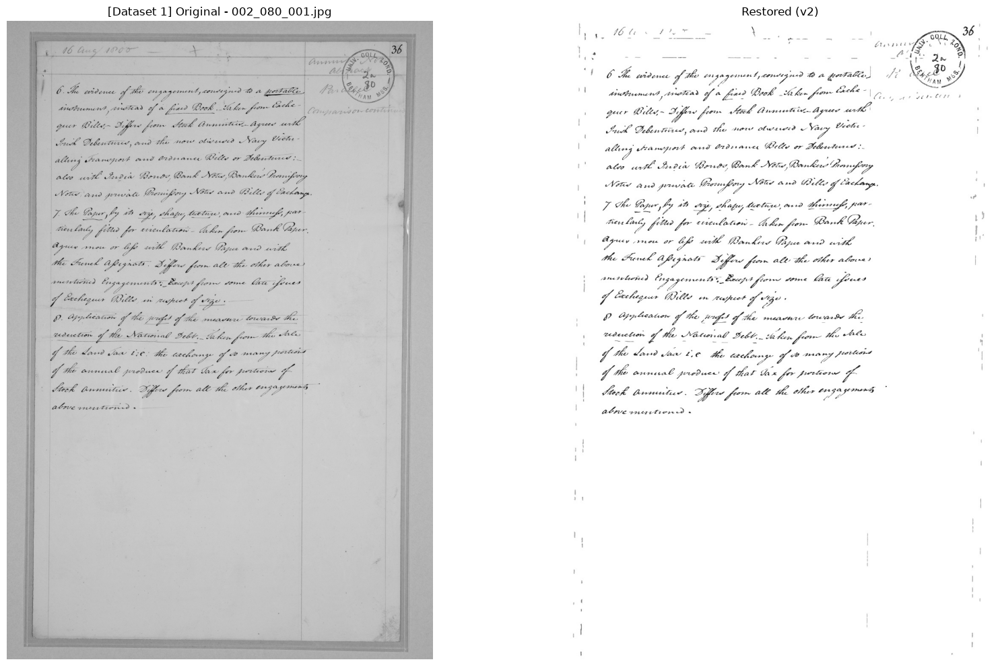

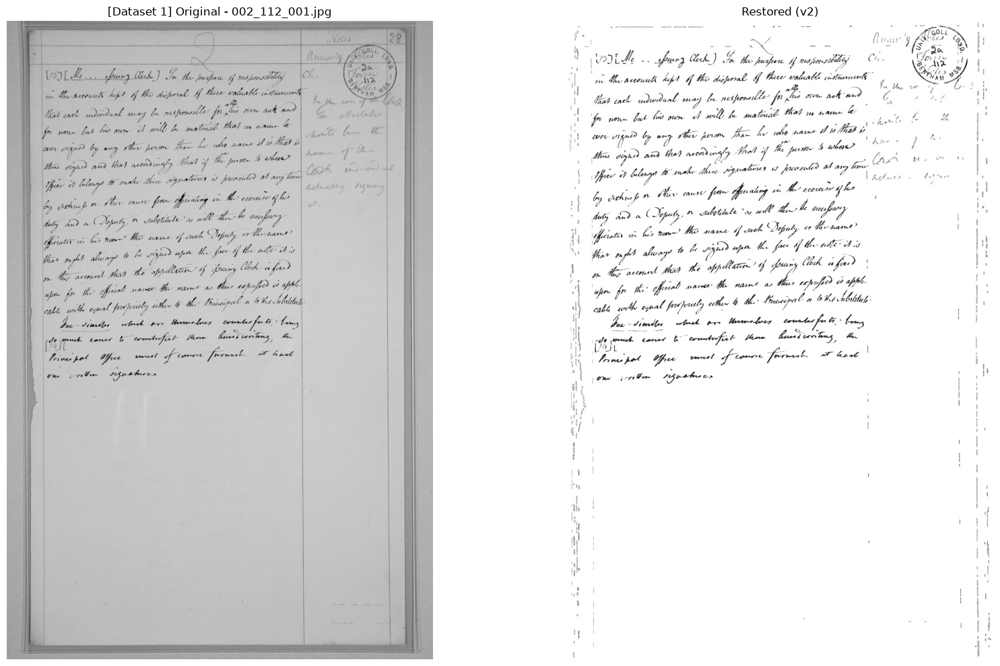

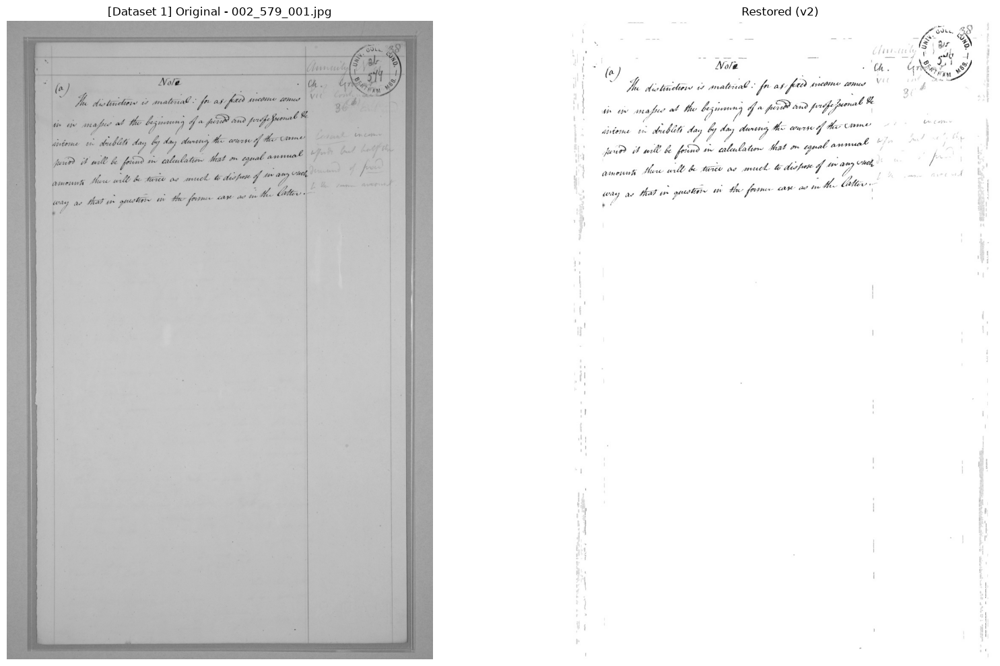

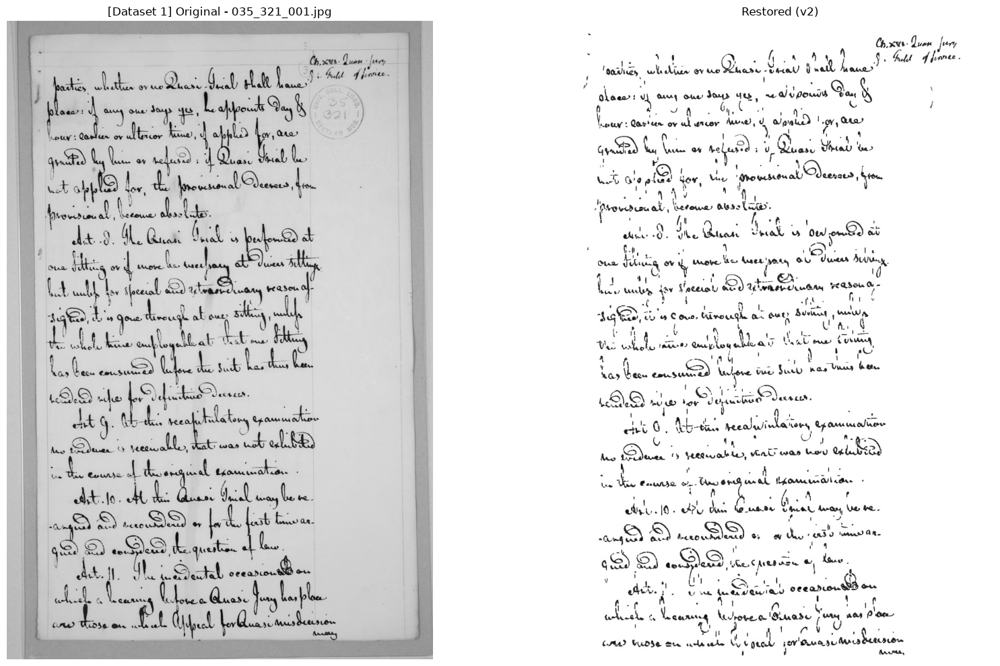

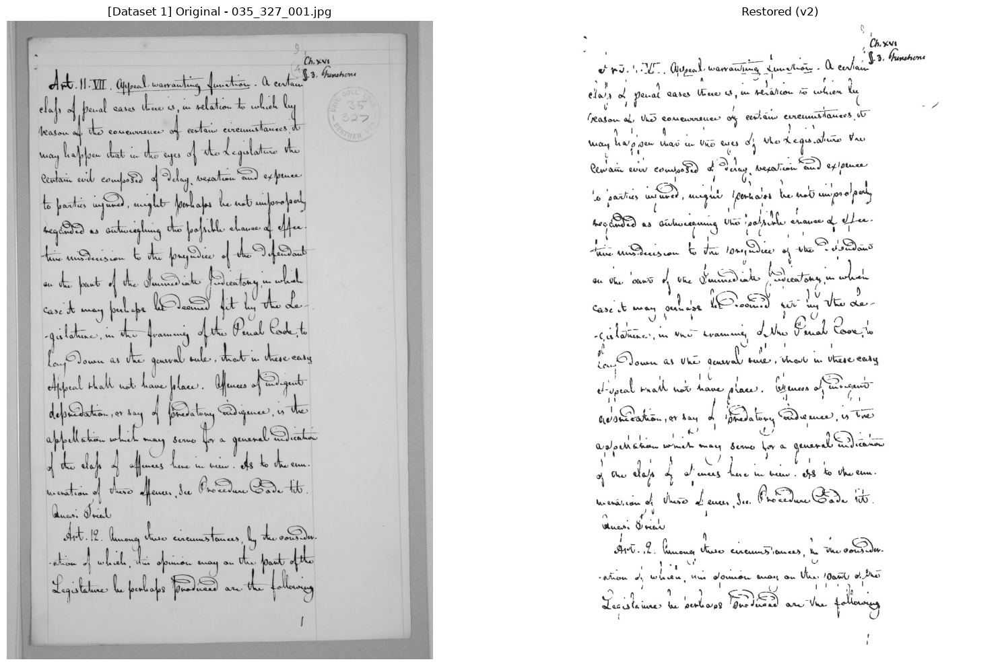

In [12]:
# First dataset (local dataset/ folder): original vs. restored, first 5
# Paths are explicit so this works regardless of what INPUT_DIR / OUTPUT_DIR point to.
DS1_INPUT = os.path.join(os.getcwd(), "dataset")
DS1_OUTPUT = os.path.join(os.getcwd(), "dataset_restored")
ds1_files = sorted(f for f in os.listdir(DS1_INPUT)
                   if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")))

for fname in ds1_files[:5]:
	orig = cv2.imread(os.path.join(DS1_INPUT, fname), cv2.IMREAD_GRAYSCALE)
	rest = cv2.imread(os.path.join(DS1_OUTPUT, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
	fig, axes = plt.subplots(1, 2, figsize=(18, 10))
	axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"[Dataset 1] Original - {fname}"); axes[0].axis("off")
	if rest is not None:
		axes[1].imshow(rest, cmap="gray")
	axes[1].set_title("Restored (v2)"); axes[1].axis("off")
	plt.tight_layout()
	plt.show()


## 7. Persian Heritage dataset (`persian/` -> `persian_restored/`)

Runs the unchanged `restore_document_v2` pipeline on every image in the `persian/` folder, saves results to `persian_restored/` only, then shows original vs. processed for the first 5 images. Needs the imports (cell 1) and the pipeline functions (sections 2-3) to have been run.

In [13]:
import shutil

PERSIAN_DIR = os.path.join(os.getcwd(), "persian")
PERSIAN_OUT = os.path.join(os.getcwd(), "persian_restored")

persian_files = sorted(f for f in os.listdir(PERSIAN_DIR)
                       if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")))

if os.path.exists(PERSIAN_OUT):
	shutil.rmtree(PERSIAN_OUT)
os.makedirs(PERSIAN_OUT, exist_ok=True)

persian_failed = []
for fname in tqdm(persian_files, desc="Restoring persian/"):
	out_path = os.path.join(PERSIAN_OUT, os.path.splitext(fname)[0] + ".jpg")
	try:
		result = restore_document_v2(os.path.join(PERSIAN_DIR, fname))
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			persian_failed.append(fname)
	except Exception as e:
		persian_failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(persian_files) - len(persian_failed)} / Failed: {len(persian_failed)} / Total: {len(persian_files)}")


Restoring persian/:   0%|          | 0/15 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
Restoring persian/: 100%|██████████| 15/15 [00:09<00:00,  1.51it/s]

Done. Restored: 15 / Failed: 0 / Total: 15


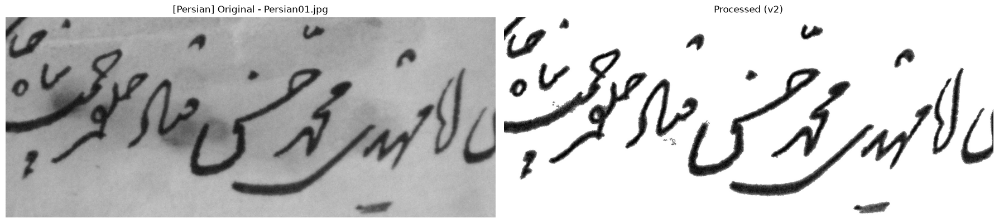

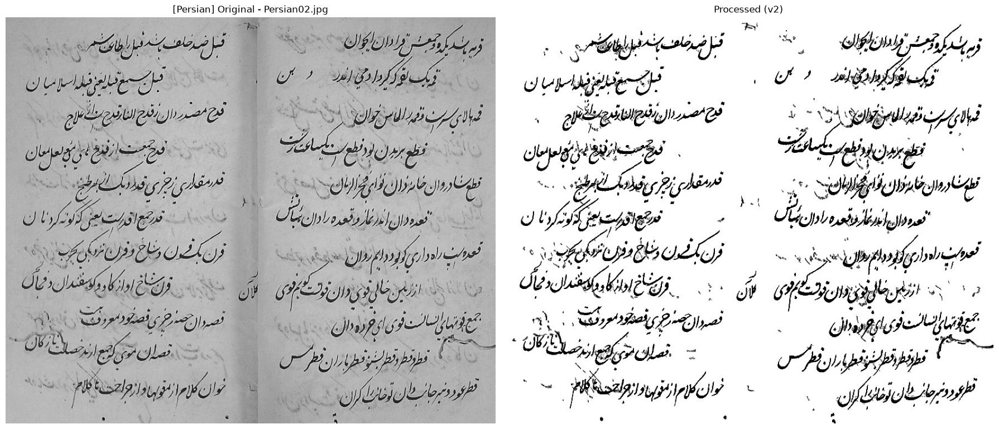

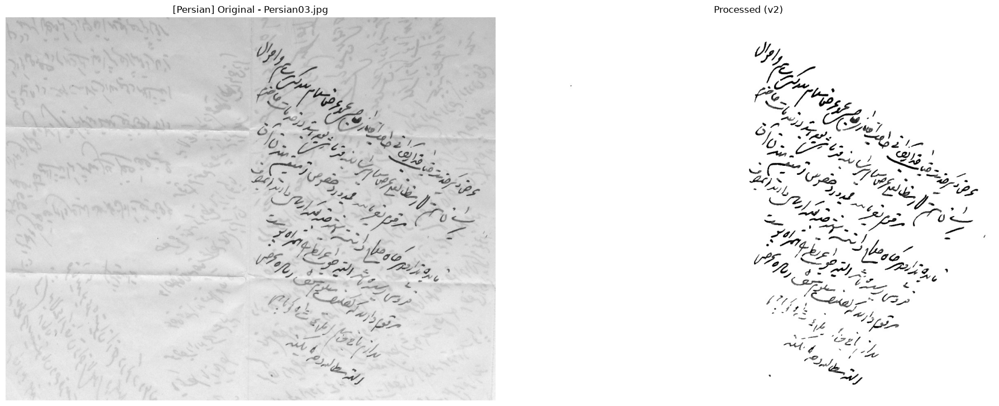

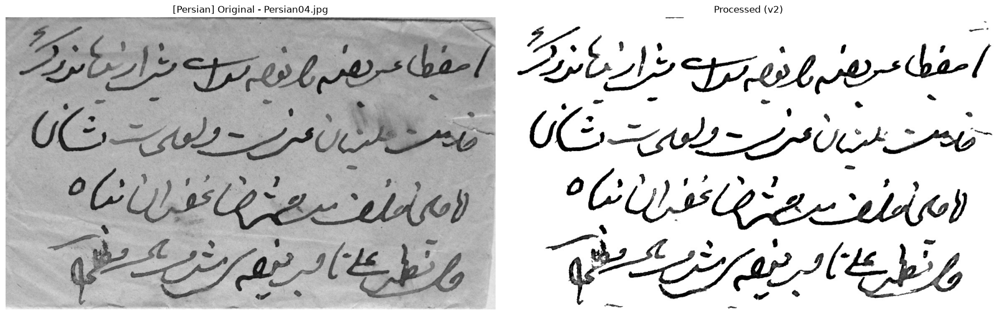

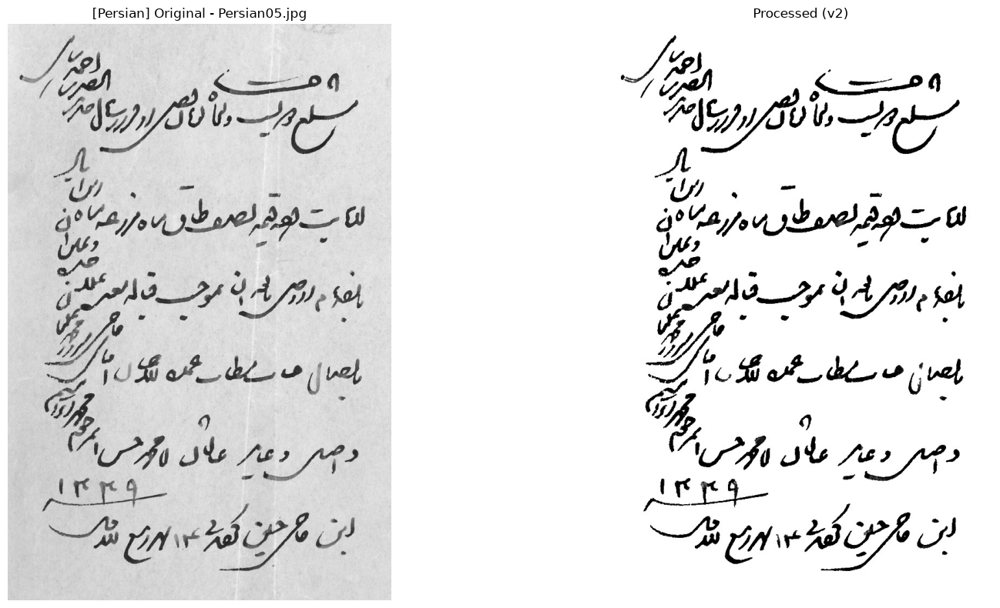

In [14]:
N_SHOW = 5
for fname in persian_files[:N_SHOW]:
	orig = cv2.imread(os.path.join(PERSIAN_DIR, fname), cv2.IMREAD_GRAYSCALE)
	rest = cv2.imread(os.path.join(PERSIAN_OUT, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
	fig, axes = plt.subplots(1, 2, figsize=(18, 8))
	axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"[Persian] Original - {fname}"); axes[0].axis("off")
	if rest is not None:
		axes[1].imshow(rest, cmap="gray")
	axes[1].set_title("Processed (v2)"); axes[1].axis("off")
	plt.tight_layout()
	plt.show()


Restoring dibco_2017/:   0%|          | 0/20 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
Restoring dibco_2017/: 100%|██████████| 20/20 [00:19<00:00,  1.03it/s]


Done. Restored: 20 / Failed: 0 / Total: 20


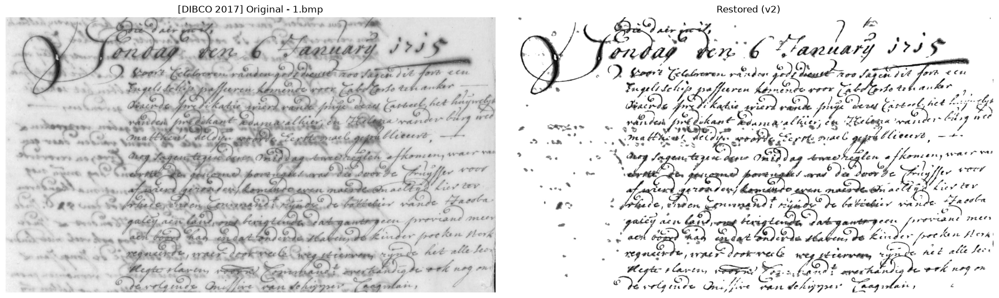

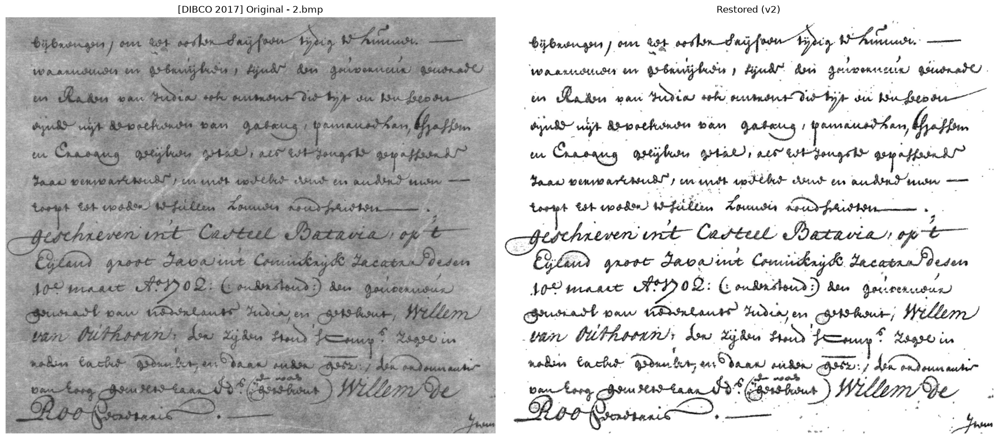

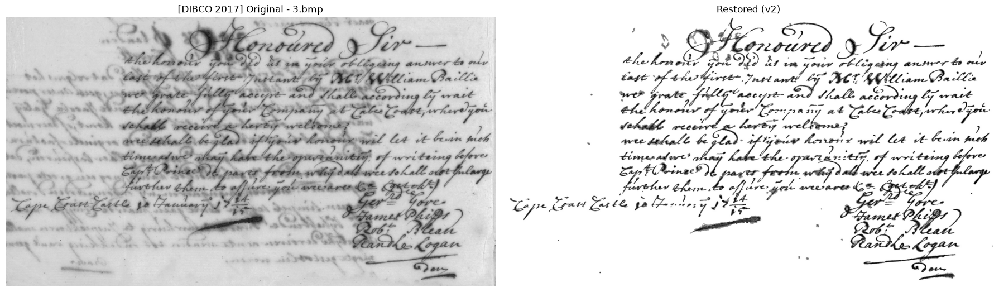

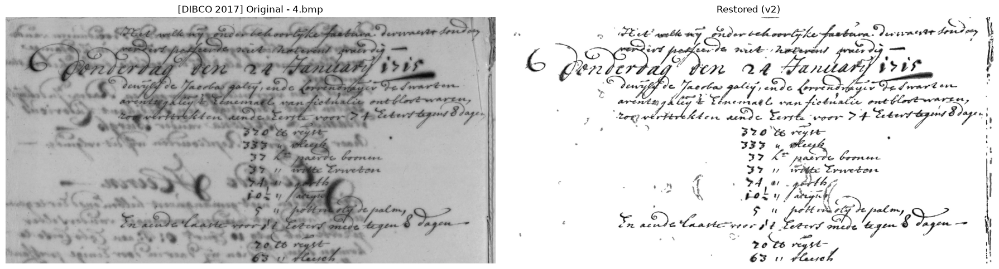

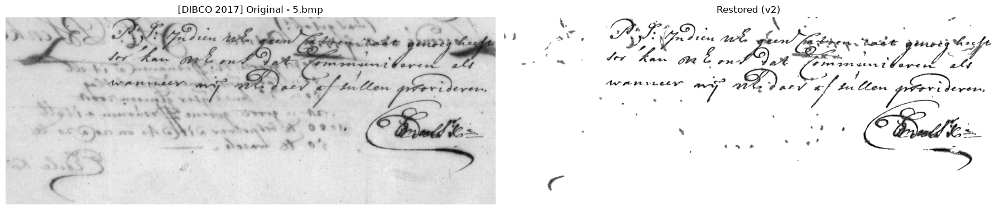

In [15]:
# DIBCO 2017 (dibco_2017/ -> dibco_2017_restored/): restore every image, then show original vs. restored for the first 5
# Needs the imports cell and the pipeline functions (sections 2-3) to have been run.
import re, shutil

D17_DIR = os.path.join(os.getcwd(), "dibco_2017")
D17_OUT = os.path.join(os.getcwd(), "dibco_2017_restored")

# natural sort so 2.bmp comes before 10.bmp
d17_files = sorted((f for f in os.listdir(D17_DIR)
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"))),
                   key=lambda f: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", f)])

if os.path.exists(D17_OUT):
	shutil.rmtree(D17_OUT)
os.makedirs(D17_OUT, exist_ok=True)

d17_failed = []
for fname in tqdm(d17_files, desc="Restoring dibco_2017/"):
	out_path = os.path.join(D17_OUT, os.path.splitext(fname)[0] + ".jpg")
	try:
		result = restore_document_v2(os.path.join(D17_DIR, fname))
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			d17_failed.append(fname)
	except Exception as e:
		d17_failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(d17_files) - len(d17_failed)} / Failed: {len(d17_failed)} / Total: {len(d17_files)}")

for fname in d17_files[:5]:
	orig = cv2.imread(os.path.join(D17_DIR, fname), cv2.IMREAD_GRAYSCALE)
	rest = cv2.imread(os.path.join(D17_OUT, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
	fig, axes = plt.subplots(1, 2, figsize=(18, 8))
	axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"[DIBCO 2017] Original - {fname}"); axes[0].axis("off")
	if rest is not None:
		axes[1].imshow(rest, cmap="gray")
	axes[1].set_title("Restored (v2)"); axes[1].axis("off")
	plt.tight_layout()
	plt.show()


Restoring dibco_2018/:   0%|          | 0/10 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_18136\259286143.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  text = remove_small_objects(text, max(3, stroke_r), connectivity=2)   # keep dots, full stops, diacritics
Restoring dibco_2018/: 100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


Done. Restored: 10 / Failed: 0 / Total: 10


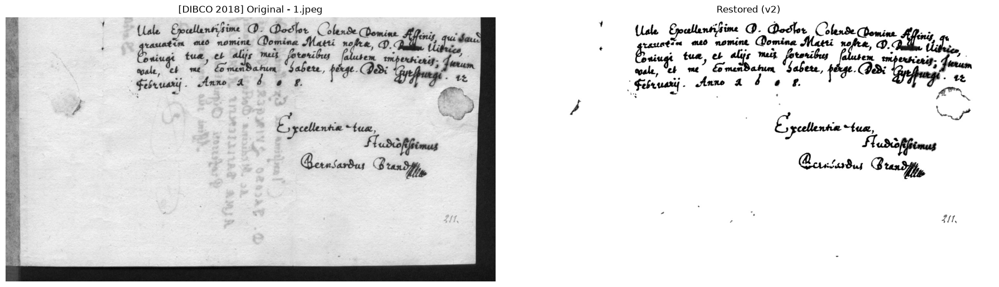

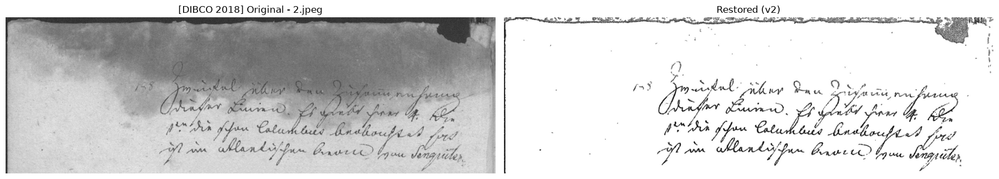

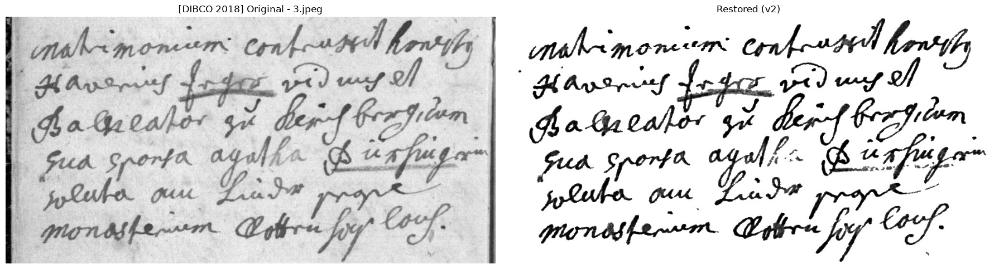

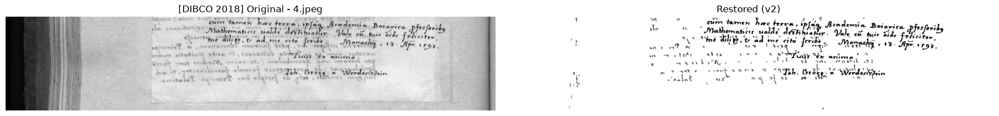

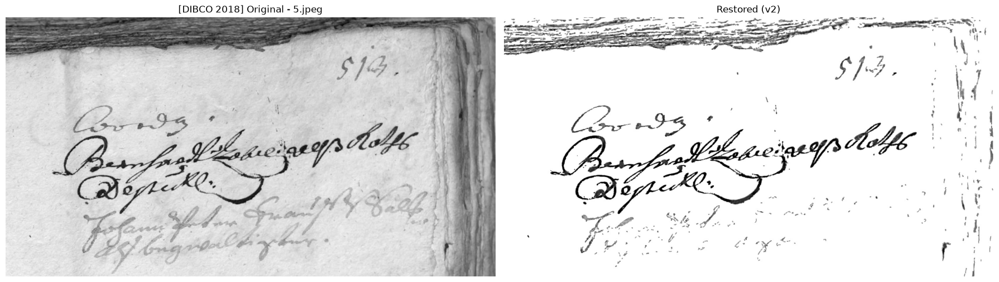

In [16]:
# DIBCO 2018 (dibco_2018/ -> dibco_2018_restored/): restore every image, then show original vs. restored for the first 5
# Needs the imports cell and the pipeline functions (sections 2-3) to have been run.
import re, shutil

D18_DIR = os.path.join(os.getcwd(), "dibco_2018")
D18_OUT = os.path.join(os.getcwd(), "dibco_2018_restored")

# natural sort so 2.jpeg comes before 10.jpeg
d18_files = sorted((f for f in os.listdir(D18_DIR)
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"))),
                   key=lambda f: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", f)])

if os.path.exists(D18_OUT):
	shutil.rmtree(D18_OUT)
os.makedirs(D18_OUT, exist_ok=True)

d18_failed = []
for fname in tqdm(d18_files, desc="Restoring dibco_2018/"):
	out_path = os.path.join(D18_OUT, os.path.splitext(fname)[0] + ".jpg")
	try:
		result = restore_document_v2(os.path.join(D18_DIR, fname))
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			d18_failed.append(fname)
	except Exception as e:
		d18_failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(d18_files) - len(d18_failed)} / Failed: {len(d18_failed)} / Total: {len(d18_files)}")

for fname in d18_files[:5]:
	orig = cv2.imread(os.path.join(D18_DIR, fname), cv2.IMREAD_GRAYSCALE)
	rest = cv2.imread(os.path.join(D18_OUT, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
	fig, axes = plt.subplots(1, 2, figsize=(18, 8))
	axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"[DIBCO 2018] Original - {fname}"); axes[0].axis("off")
	if rest is not None:
		axes[1].imshow(rest, cmap="gray")
	axes[1].set_title("Restored (v2)"); axes[1].axis("off")
	plt.tight_layout()
	plt.show()
